In [2]:
import pandas as pd
df = pd.read_csv("train.csv")
print(df.shape)
print(df.isnull().sum())
print(df.groupby("Sex")["Survived"].mean())
print(df.groupby("Pclass")["Survived"].mean())

(891, 12)
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


In [5]:
# Survival by age group
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 12, 18, 40, 60, 100],
                        labels=["Child", "Teen", "Adult", "Middle", "Senior"])
print(df.groupby("AgeGroup", observed=True)["Survived"].mean())

# Gender and class together
print(df.groupby(["Sex", "Pclass"])["Survived"].mean())

# Fare vs survival
print(df.groupby("Survived")["Fare"].mean())

AgeGroup
Child     0.579710
Teen      0.428571
Adult     0.388235
Middle    0.390625
Senior    0.227273
Name: Survived, dtype: float64
Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64
Survived
0    22.117887
1    48.395408
Name: Fare, dtype: float64


In [6]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df = df.drop(columns=["Cabin"])
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         0
AgeGroup       177
dtype: int64


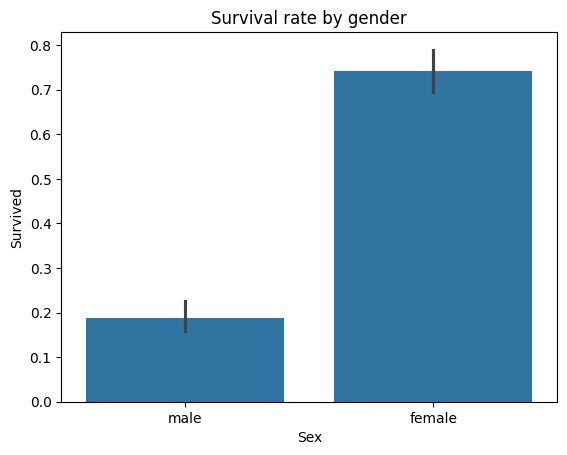

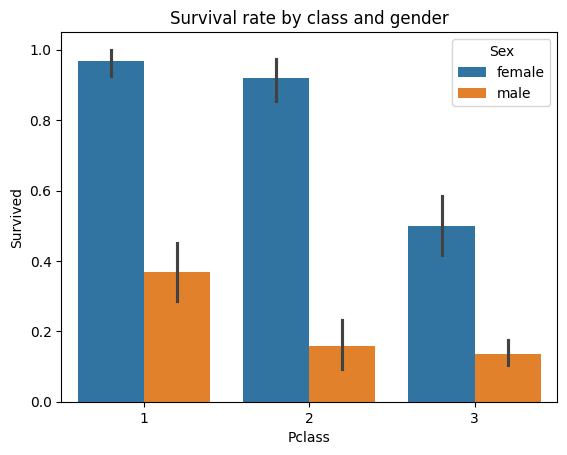

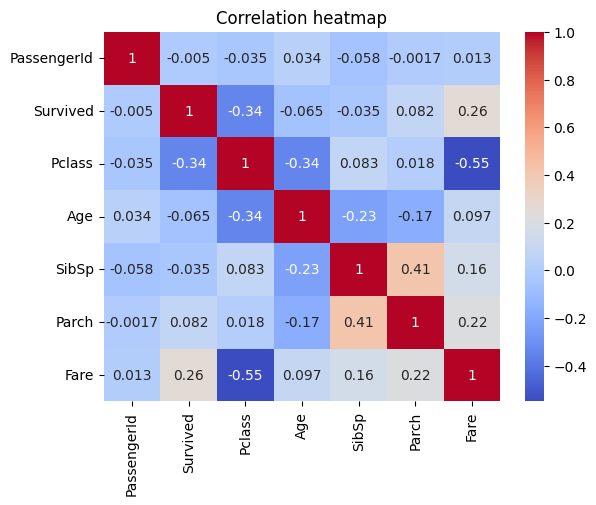

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(x="Sex", y="Survived", data=df)
plt.title("Survival rate by gender")
plt.show()

sns.barplot(x="Pclass", y="Survived", hue="Sex", data=df)
plt.title("Survival rate by class and gender")
plt.show()

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

Women survived at 74% versus 19% for men.
First class had 63% survival versus 24% in third class.
Gender and class together mattered most: 97% of first-class women survived.
Passengers who survived paid a higher average fare.
Age had a smaller effect, but children had better survival.